# 03 · Revisión manual de calidad de etiquetas

Rúbrica B5. El artículo original de Food-101 advierte que **las imágenes de entrenamiento no se limpiaron a propósito** y contienen ruido (colores intensos y algunas etiquetas incorrectas). Revisamos una muestra aleatoria fija de **40 imágenes de train**; el veredicto de cada una está en `docs/revision_etiquetas.csv`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.config import *
sns.set_theme(style="whitegrid")
FIG_DIR.mkdir(parents=True, exist_ok=True)

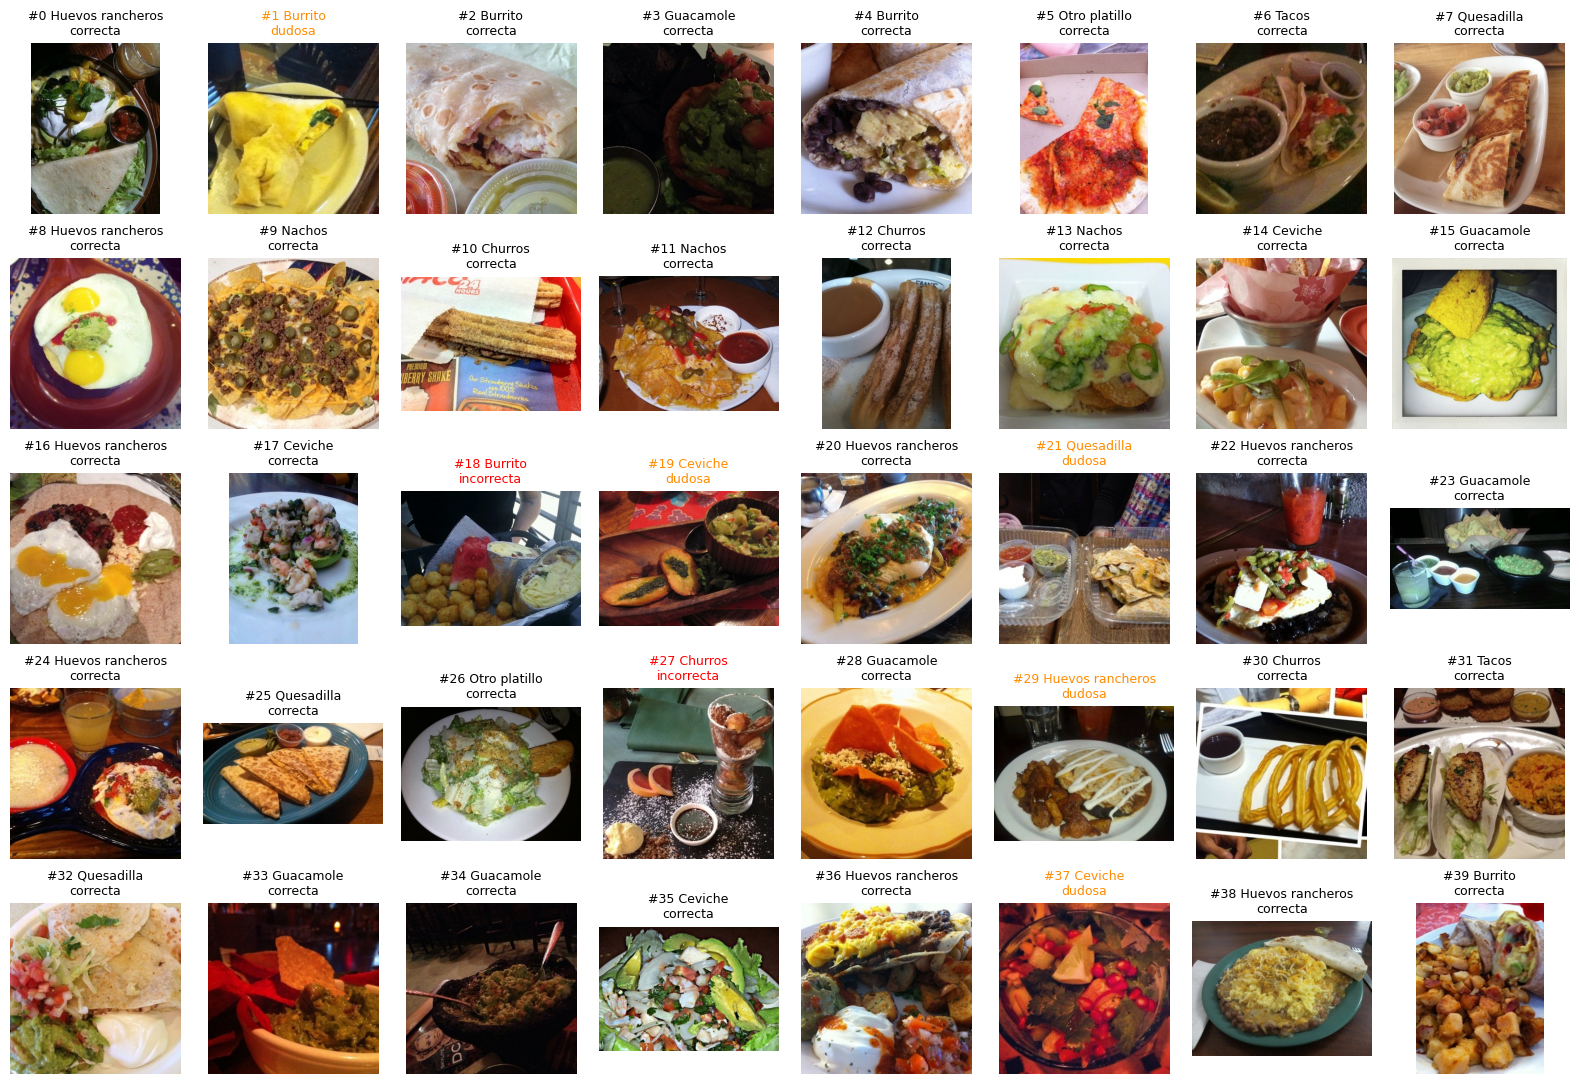

In [2]:
from PIL import Image
# Muestra aleatoria fija (semilla 42) tomada de train ANTES de la corrección; el veredicto se registró a mano.
rev = pd.read_csv(ROOT / "docs" / "revision_etiquetas.csv")
colors = {"correcta": "black", "dudosa": "darkorange", "incorrecta": "red"}
fig, axes = plt.subplots(5, 8, figsize=(16, 11))
for ax, (_, r) in zip(axes.flat, rev.iterrows()):
    ax.imshow(Image.open(ROOT / r.path)); ax.axis("off")
    ax.set_title(f"#{r.id} {DISPLAY[r.label]}\n{r.veredicto}", fontsize=9, color=colors[r.veredicto])
plt.tight_layout(); plt.savefig(FIG_DIR / "revision_etiquetas.png", dpi=80); plt.show()

In [3]:
err = rev[rev.veredicto != "correcta"]
print(f"Revisadas: {len(rev)}")
for v in ("incorrecta", "dudosa"):
    n = (rev.veredicto == v).sum(); print(f"  {v}: {n} ({n / len(rev):.1%})")
rep = json.load(open(SPLITS_DIR / "reporte_particiones.json"))
print("Excluidas de train por make_splits:", rep["removed_wrong_label"])

Revisadas: 40
  incorrecta: 2 (5.0%)
  dudosa: 5 (12.5%)
Excluidas de train por make_splits: ['data/raw/breakfast_burrito/752124.jpg', 'data/raw/churros/2836649.jpg']


In [4]:
err[['label', 'veredicto', 'comentario']]

,label,veredicto,comentario
1,breakfast_burrito,dudosa,Parece omelette o crepa; no se distingue la to...
18,breakfast_burrito,incorrecta,Solo se ven papas (tater tots) y salsas; no ha...
19,ceviche,dudosa,Plátano frito con salsa/guacamole; el ceviche ...
21,chicken_quesadilla,dudosa,Contenedores para llevar con totopos y salsas;...
27,churros,incorrecta,Postre en vaso; no hay churros visibles
29,huevos_rancheros,dudosa,Parecen enchiladas con crema y plátano
37,ceviche,dudosa,Parece ensalada de frutas con granada


**Corrección aplicada:** (1) las imágenes marcadas como `incorrecta` se **excluyen de train** automáticamente en `src/make_splits.py`; (2) las `dudosa` se conservan (el platillo podría estar presente pero poco visible) y (3) como el error estimado no es cero en el resto de train, se usa **label smoothing (0.1)** en la pérdida, que reduce la sobreconfianza ante etiquetas erróneas. Las imágenes de prueba (test) sí fueron limpiadas manualmente por los autores del dataset.